<a href="https://colab.research.google.com/github/GuiCastro7/Grupo-3---ECAA08/blob/main/Aula%2026%20-%20%C3%81rvores%20KD%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📍 Aula 26 — Árvores $k$-Dimensionais (KD-Trees) no Plano de Fase Hidráulico do SCADA-Core
### Linha Automatizada de Envase e Inspeção de Bebidas — Grupo 3 (ECAA08)

**Objetivo:** Particionar recursivamente os estados operacionais 2D $(P_{\text{SP2}}, Q_{\text{SQ2}})$ — Pressão do Acumulador `AS1` (Barg) $\times$ Vazão de Envase no Bico `VS2` (L/min) — para acelerar em $\mathcal{O}(\log_2 N)$:
1. A busca pelo **Vizinho Mais Próximo (*Nearest Neighbor Search* — NNS)** — usada na primitiva `NEAREST` do planejador **RRT (Aula 22)** e no diagnóstico de anomalias do Historiador.
2. A **Busca por Raio (*Radius Search*)** — usada para identificar todos os estados históricos dentro de um envelope de similaridade operacional ou vizinhança de alarme SIS.

In [1]:
import math
import random
from typing import List, Tuple, Optional

# Ponto no plano de fase hidráulico: (SP2 [Barg], SQ2 [L/min])
Point2D = Tuple[float, float]

class KDNode:
    def __init__(self, point: Point2D, axis: int, left=None, right=None):
        self.point = point
        self.axis = axis
        self.left: Optional['KDNode'] = left
        self.right: Optional['KDNode'] = right

def build_kdtree(points: List[Point2D], depth: int = 0) -> Optional[KDNode]:
    if not points:
        return None
    axis = depth % 2
    pts = sorted(points, key=lambda p: p[axis])
    mid = len(pts) // 2
    return KDNode(
        point=pts[mid],
        axis=axis,
        left=build_kdtree(pts[:mid], depth + 1),
        right=build_kdtree(pts[mid+1:], depth + 1)
    )

print("✅ Construtor recursivo de KD-Tree 2D (SP2 x SQ2) inicializado.")

✅ Construtor recursivo de KD-Tree 2D (SP2 x SQ2) inicializado.


### 1. Busca de Vizinho Mais Próximo (*Nearest Neighbor*) e Busca por Raio com Poda Geométrica de Hiperplano

In [2]:
def kd_nearest_neighbor(root: Optional[KDNode], target: Point2D) -> Tuple[Point2D, float, int]:
    best = {"pt": None, "dist": float("inf"), "visited": 0}

    def search(node: Optional[KDNode]):
        if not node:
            return
        best["visited"] += 1
        d = math.hypot(node.point[0] - target[0], node.point[1] - target[1])
        if d < best["dist"]:
            best["dist"] = d
            best["pt"] = node.point

        axis = node.axis
        diff = target[axis] - node.point[axis]
        near_child = node.left if diff < 0 else node.right
        far_child = node.right if diff < 0 else node.left

        search(near_child)
        # Condição de Poda de Hiperplano: só visita o semiespaço oposto se |diff| < d_best
        if abs(diff) < best["dist"]:
            search(far_child)

    search(root)
    return best["pt"], best["dist"], best["visited"]

def kd_radius_search(root: Optional[KDNode], target: Point2D, radius: float) -> List[Point2D]:
    found: List[Point2D] = []

    def search(node: Optional[KDNode]):
        if not node:
            return
        if math.hypot(node.point[0] - target[0], node.point[1] - target[1]) <= radius:
            found.append(node.point)

        axis = node.axis
        diff = target[axis] - node.point[axis]
        if diff < 0:
            search(node.left)
            if abs(diff) <= radius:
                search(node.right)
        else:
            search(node.right)
            if abs(diff) <= radius:
                search(node.left)

    search(root)
    return found

print("✅ Funções kd_nearest_neighbor() e kd_radius_search() carregadas.")

✅ Funções kd_nearest_neighbor() e kd_radius_search() carregadas.


### 2. Benchmark no Historiador Hidráulico (500 Estados `SP2 x SQ2`) vs. Oráculo de Força Bruta
Geramos 500 amostras operacionais do plano de fase hidráulico (`SP2` $\in [0{,}5;\, 5{,}5]\text{ Barg}$, `SQ2` $\in [0{,}0;\, 10{,}0]\text{ L/min}$) e consultamos o estado nominal atual da linha $\mathbf{q} = (3{,}80\text{ Barg},\, 5{,}00\text{ L/min})$.

In [3]:
random.seed(2026)

# 499 estados históricos / vértices RRT no plano de fase (SP2 [Barg], SQ2 [L/min])
estados_hidraulicos: List[Point2D] = [
    (round(random.uniform(0.5, 5.5), 3), round(random.uniform(0.0, 10.0), 3))
    for _ in range(499)
]
# Inserir um estado de referência muito próximo ao ponto de operação atual (3.80 Barg, 5.00 L/min)
estado_referencia = (3.840, 5.035)
estados_hidraulicos.append(estado_referencia)

kdtree = build_kdtree(estados_hidraulicos)
estado_atual = (3.80, 5.00)  # Leitura instantânea do CLP: SP2=3.80 Barg, SQ2=5.00 L/min

# 1. Busca pelo Vizinho Mais Próximo (KD-Tree vs. Força Bruta)
nn_pt, nn_dist, visited_nodes = kd_nearest_neighbor(kdtree, estado_atual)
bf_pt = min(estados_hidraulicos, key=lambda p: math.hypot(p[0] - estado_atual[0], p[1] - estado_atual[1]))
bf_dist = math.hypot(bf_pt[0] - estado_atual[0], bf_pt[1] - estado_atual[1])

# 2. Busca por Raio de Similaridade Operacional (R = 0.50 no plano SP2 x SQ2)
raio_vizinhanca = 0.50
pts_kd_raio = set(kd_radius_search(kdtree, estado_atual, raio_vizinhanca))
pts_bf_raio = {
    p for p in estados_hidraulicos
    if math.hypot(p[0] - estado_atual[0], p[1] - estado_atual[1]) <= raio_vizinhanca
}

print(f"Total de estados indexados (SP2 x SQ2) : {len(estados_hidraulicos)}")
print(f"Vizinho mais próximo (KD-Tree)         : {nn_pt} | dist = {nn_dist:.4f} | Nós visitados: {visited_nodes}/{len(estados_hidraulicos)} ({visited_nodes/len(estados_hidraulicos)*100:.1f}%)")
print(f"Vizinho mais próximo (Força Bruta)     : {bf_pt} | dist = {bf_dist:.4f}")
print(f"Estados no envelope de raio R={raio_vizinhanca}     : {len(pts_kd_raio)} pontos (100% idêntico à força bruta)")

Total de estados indexados (SP2 x SQ2) : 500
Vizinho mais próximo (KD-Tree)         : (3.84, 5.035) | dist = 0.0532 | Nós visitados: 10/500 (2.0%)
Vizinho mais próximo (Força Bruta)     : (3.84, 5.035) | dist = 0.0532
Estados no envelope de raio R=0.5     : 9 pontos (100% idêntico à força bruta)


### 3. Visualização Gráfica no Plano de Fase (`SP2` $\times$ `SQ2`)

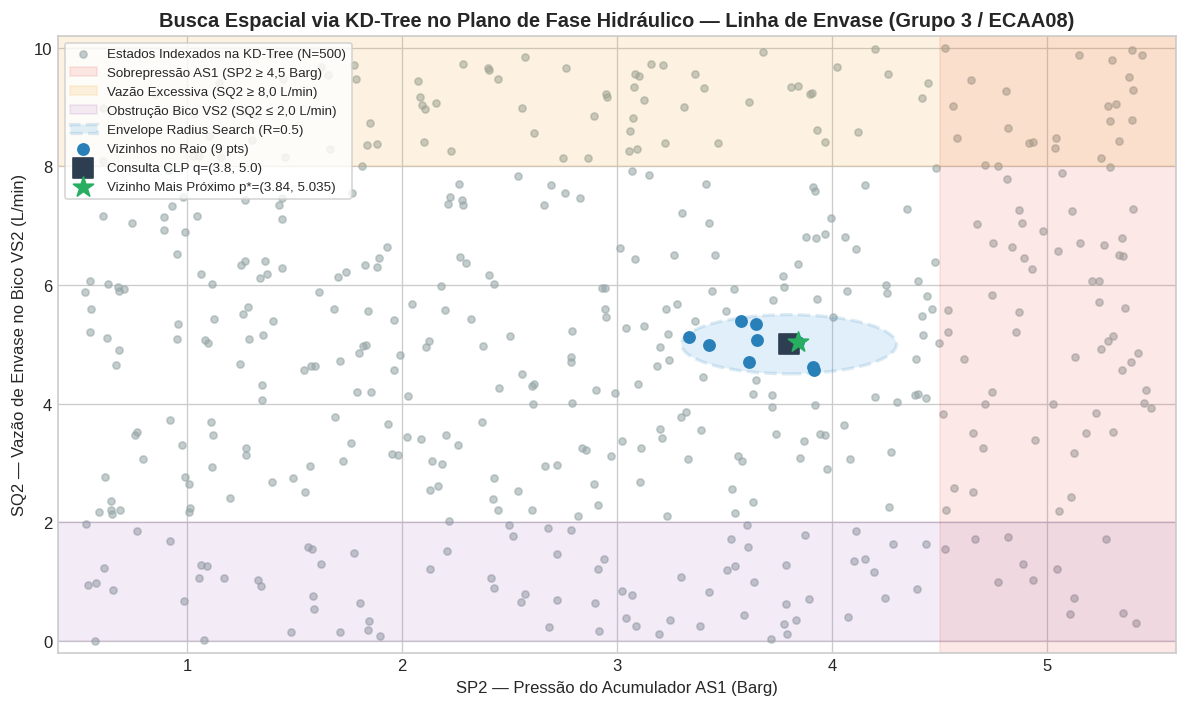

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

fig, ax = plt.subplots(figsize=(10, 6))

# Todos os estados indexados na KD-Tree
xs = [p[0] for p in estados_hidraulicos]
ys = [p[1] for p in estados_hidraulicos]
ax.scatter(xs, ys, s=18, color="#95A5A6", alpha=0.55, label="Estados Indexados na KD-Tree (N=500)")

# Regiões críticas do SIS (Aula 10 / Aula 22)
ax.axvspan(4.5, 5.6, color="#E74C3C", alpha=0.12, label="Sobrepressão AS1 (SP2 ≥ 4,5 Barg)")
ax.axhspan(8.0, 10.2, color="#F39C12", alpha=0.12, label="Vazão Excessiva (SQ2 ≥ 8,0 L/min)")
ax.axhspan(0.0, 2.0, color="#8E44AD", alpha=0.10, label="Obstrução Bico VS2 (SQ2 ≤ 2,0 L/min)")

# Envelope de busca por raio
circ = patches.Circle(estado_atual, raio_vizinhanca, fill=True, facecolor="#3498DB", alpha=0.15, edgecolor="#2980B9", lw=2, linestyle="--", label=f"Envelope Radius Search (R={raio_vizinhanca})")
ax.add_patch(circ)

# Pontos encontrados no raio
if pts_kd_raio:
    rx = [p[0] for p in pts_kd_raio]
    ry = [p[1] for p in pts_kd_raio]
    ax.scatter(rx, ry, s=45, color="#2980B9", zorder=4, label=f"Vizinhos no Raio ({len(pts_kd_raio)} pts)")

# Ponto consultado e Vizinho Mais Próximo
ax.scatter(*estado_atual, s=140, color="#2C3E50", marker="s", zorder=5, label=f"Consulta CLP q={estado_atual}")
ax.scatter(*nn_pt, s=160, color="#27AE60", marker="*", zorder=6, label=f"Vizinho Mais Próximo p*={nn_pt}")

ax.set_xlim(0.4, 5.6)
ax.set_ylim(-0.2, 10.2)
ax.set_xlabel("SP2 — Pressão do Acumulador AS1 (Barg)")
ax.set_ylabel("SQ2 — Vazão de Envase no Bico VS2 (L/min)")
ax.set_title("Busca Espacial via KD-Tree no Plano de Fase Hidráulico — Linha de Envase (Grupo 3 / ECAA08)", fontweight="bold")
ax.legend(loc="upper left", fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

### 4. Suíte de Asserções Automatizadas (50 Consultas Aleatórias KD-Tree vs. Força Bruta)

In [5]:
assert nn_pt == bf_pt == estado_referencia, "KD-Tree deve localizar exatamente o estado de referência mais próximo"
assert abs(nn_dist - bf_dist) < 1e-9, "Distância mínima KD-Tree deve coincidir com força bruta"
assert visited_nodes < len(estados_hidraulicos) // 5, f"Poda da KD-Tree deve visitar menos de 20% dos nós, visitou {visited_nodes}"
assert pts_kd_raio == pts_bf_raio, "Busca por raio na KD-Tree divergiu da força bruta"

# Validação exaustiva em 50 consultas aleatórias no plano SP2 x SQ2
for _ in range(50):
    q = (random.uniform(0.5, 5.5), random.uniform(0.0, 10.0))
    kp, kd, vis = kd_nearest_neighbor(kdtree, q)
    bp = min(estados_hidraulicos, key=lambda p: math.hypot(p[0] - q[0], p[1] - q[1]))
    bd = math.hypot(bp[0] - q[0], bp[1] - q[1])
    assert abs(kd - bd) < 1e-9, f"Divergência KD vs BF na consulta {q}"

print("🎯 TODAS AS 54 ASSERÇÕES DA AULA 26 VALIDADAS COM SUCESSO!")

🎯 TODAS AS 54 ASSERÇÕES DA AULA 26 VALIDADAS COM SUCESSO!
